In [1]:
import os

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs

from functools import partial

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
from mlflow.tracking import MlflowClient

/Users/timith/miniconda3/envs/nese-anemoi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
plt.style.use("../../nice.mplstyle")

## Reading the offline mlflow store

In [3]:
def open_run(tracking_dir, experiment_name=None, run_id=None):
    """Return (client, run) for one offline mlflow run, defaulting to the most recent."""
    client = MlflowClient(tracking_uri=f"file://{os.path.abspath(tracking_dir)}")
    experiments = client.search_experiments()
    if experiment_name is not None:
        experiments = [e for e in experiments if e.name == experiment_name]
    runs = client.search_runs([e.experiment_id for e in experiments], order_by=["attributes.start_time DESC"])
    if run_id is not None:
        runs = [r for r in runs if r.info.run_id == run_id]
    return client, runs[0]


def read_metric(client, run, key):
    """One metric as a pandas Series indexed by training step."""
    history = client.get_metric_history(run.info.run_id, key)
    df = pd.DataFrame(
        {
            "step": [m.step for m in history],
            "value": [m.value for m in history],
        }
    ).drop_duplicates(subset="step", keep="last")
    return df.set_index("step")["value"].rename(key).sort_index()


def read_metrics(client, run, keys=None):
    """Several metrics joined on step, NaN where a metric was not logged."""
    keys = sorted(run.data.metrics) if keys is None else keys
    return pd.concat([read_metric(client, run, k) for k in keys], axis=1)

In [8]:
logname = "v3"
experiment = "v3mft"
log_dir = f"runs/{logname}"
run_dir = f"runs/{experiment}"
client, run = open_run(f"{log_dir}/logs/mlflow", experiment_name=experiment)

print(run.info.run_id, run.info.status)
print(sorted(run.data.metrics))

1fdae0085b664645ab6314db14b00a22 FINISHED
['epoch', 'lr-AdamW', 'rollout', 'train_multi_dataset_loss_epoch', 'train_multi_dataset_loss_step']


In [9]:
metrics = read_metrics(client, run)
metrics.tail()

,epoch,lr-AdamW,rollout,train_multi_dataset_loss_epoch,train_multi_dataset_loss_step
step,,,,,
259,0.0,2.555483e-06,NaN,NaN,0.516071
269,0.0,1.597955e-06,NaN,NaN,0.543023
279,0.0,8.984685e-07,NaN,NaN,0.532284
289,0.0,4.646868e-07,NaN,NaN,0.540643
299,0.0,3.013625e-07,1.0,0.595675,0.540930


## Loss curves

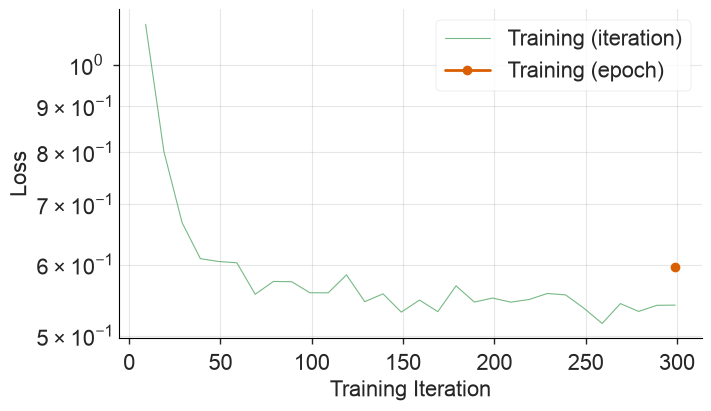

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))

metrics["train_multi_dataset_loss_step"].dropna().plot(ax=ax, lw=0.8, alpha=0.8, label="Training (iteration)")
#metrics["val_multi_dataset_loss_step"].dropna().plot(ax=ax, lw=0.8, alpha=0.8, label="Validation (iteration)")
metrics["train_multi_dataset_loss_epoch"].dropna().plot(ax=ax, marker="o", label="Training (epoch)")
#metrics["val_multi_dataset_loss_epoch"].dropna().plot(ax=ax, marker="o", label="Validation (epoch)")

ax.set(
    xlabel="Training Iteration",
    ylabel="Loss",
    yscale="log",
#    xscale="log",
)
ax.legend()
ax.grid(True, which="both", alpha=0.3)

fig.savefig(f"{run_dir}/loss_curves.pdf", bbox_inches="tight")

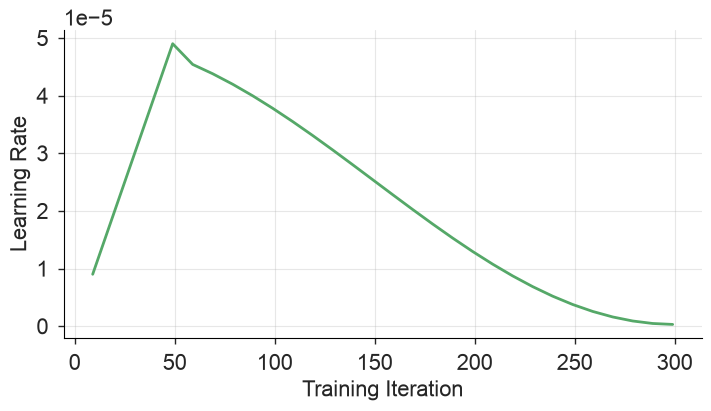

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))

metrics["lr-AdamW"].dropna().plot(ax=ax)
ax.set(xlabel="Training Iteration", ylabel="Learning Rate")
ax.grid(True, alpha=0.3)